In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

#### Description :
The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).

| Variable | Description|
| :------- | :------: |
| age | Age |
| job | type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown') |
| marital | marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed) |
| education | (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')|
| default | has credit in default? |
| balance | average yearly balance |
| housing | has housing loan? |
| loan | has personal loan? |
| contact | contact communication type (categorical: 'cellular','telephone') |
| day_of_week | last contact day of the week |
| month | last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec') |
| duration | last contact duration, in seconds (numeric). |
| campaign | number of contacts performed during this campaign and for this client (numeric, includes last contact) |
| pdays | number of days that passed by after the client was last contacted from a previous campaign (numeric; -1 means client was not previously contacted) |
| previous | number of contacts performed before this campaign and for this client |
| poutcome | outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success') |
| deposit| has the client subscribed a term deposit? |
#### Target Variable:
Target Variable: deposit

In [5]:
data = pd.read_csv('bank_campaign_for_deposit.xls')
pd.set_option('display.max_columns', None)

In [6]:
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [8]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


In [9]:
pd.isnull(data).sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [10]:
#I have "." in my job feature, i need to remove that
data["job"] = data["job"].str.replace('.', '', regex=False)

In [11]:
data.job

,job
0,admin
1,admin
2,technician
3,services
4,admin
...,...
11157,blue-collar
11158,services
11159,technician
11160,technician


In [12]:
categorical_cols = data.select_dtypes(include=['category', object])

In [13]:
categorical_cols.columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')

In [14]:
data.job.unique()

array(['admin', 'technician', 'services', 'management', 'retired',
       'blue-collar', 'unemployed', 'entrepreneur', 'housemaid',
       'unknown', 'self-employed', 'student'], dtype=object)

In [15]:
data.marital.unique()

array(['married', 'single', 'divorced'], dtype=object)

In [16]:
data.education.unique() ##unknown type needs to be treated

array(['secondary', 'tertiary', 'primary', 'unknown'], dtype=object)

In [17]:
data.education.value_counts()

,count
education,
secondary,5476
tertiary,3689
primary,1500
unknown,497


In [18]:
data.default.unique()

array(['no', 'yes'], dtype=object)

In [19]:
data.housing.unique()

array(['yes', 'no'], dtype=object)

In [20]:
data.loan.unique()

array(['no', 'yes'], dtype=object)

In [21]:
data.contact.unique()

array(['unknown', 'cellular', 'telephone'], dtype=object)

In [22]:
data.contact.value_counts()

,count
contact,
cellular,8042
unknown,2346
telephone,774


In [23]:
data.month.unique()

array(['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb',
       'mar', 'apr', 'sep'], dtype=object)

In [24]:
data.poutcome.unique()

array(['unknown', 'other', 'failure', 'success'], dtype=object)

In [25]:
data.poutcome.value_counts()

,count
poutcome,
unknown,8326
failure,1228
success,1071
other,537


In [26]:
data.deposit.unique()

array(['yes', 'no'], dtype=object)

In [27]:
#filling columns with mode
data["education"] = data["education"].fillna(data["education"].mode()[0])

In [28]:
data["contact"] = data["contact"].fillna(data["contact"].mode()[0])

In [29]:
data["poutcome"] = data["poutcome"].replace('unknown', 'other') #i want to knowingly fill values with other

In [30]:
data.poutcome.value_counts()

,count
poutcome,
other,8863
failure,1228
success,1071


In [31]:
from sklearn.preprocessing import OrdinalEncoder
oe=OrdinalEncoder()
data[['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']]=oe.fit_transform(data[['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']])

In [32]:
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,0.0,1.0,1.0,0.0,2343,1.0,0.0,2.0,5,8.0,1042,1,-1,0,1.0,1.0
1,56,0.0,1.0,1.0,0.0,45,0.0,0.0,2.0,5,8.0,1467,1,-1,0,1.0,1.0
2,41,9.0,1.0,1.0,0.0,1270,1.0,0.0,2.0,5,8.0,1389,1,-1,0,1.0,1.0
3,55,7.0,1.0,1.0,0.0,2476,1.0,0.0,2.0,5,8.0,579,1,-1,0,1.0,1.0
4,54,0.0,1.0,2.0,0.0,184,0.0,0.0,2.0,5,8.0,673,2,-1,0,1.0,1.0


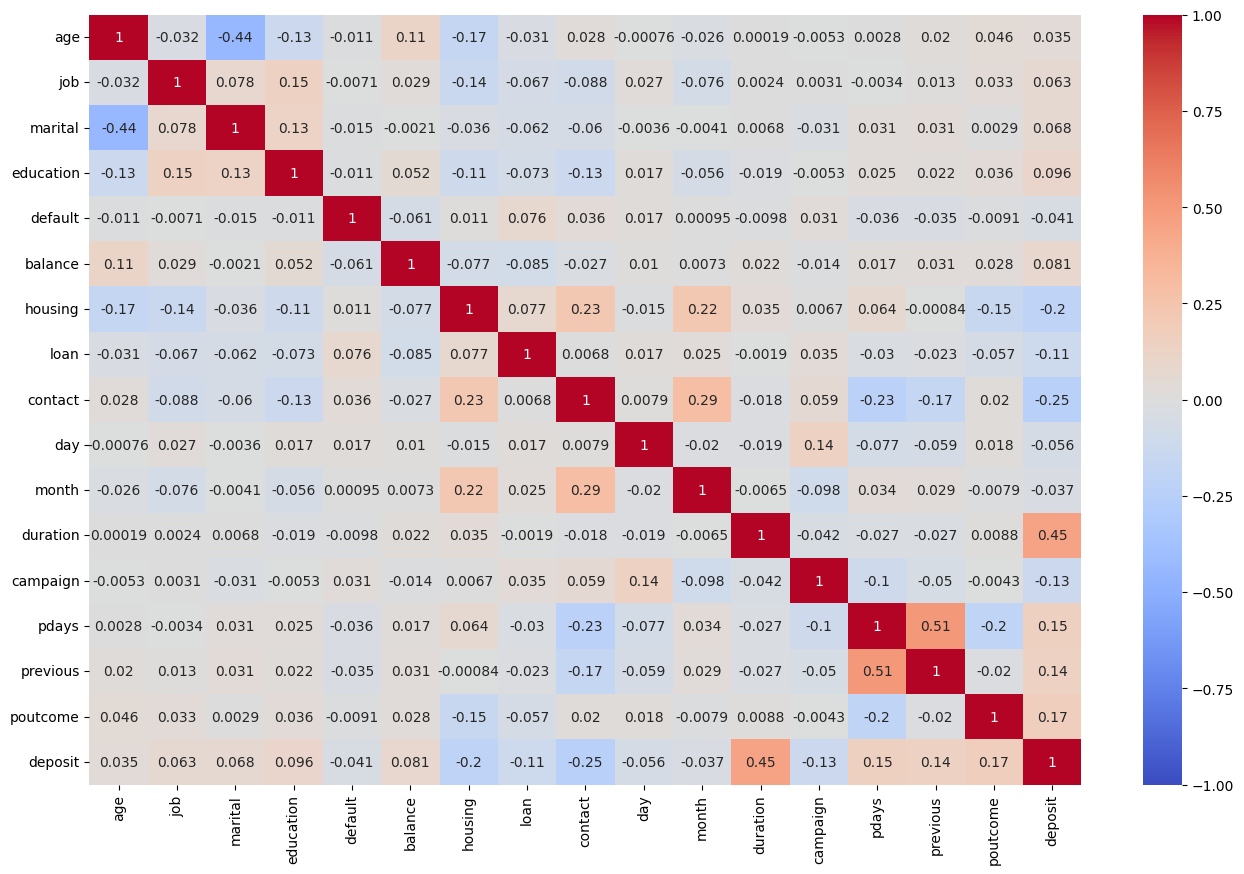

In [33]:
plt.figure(figsize=(16,10))
numeric_cols = data.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_cols.corr(), annot=True, vmin=-1, cmap='coolwarm')
plt.show()

In [34]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [35]:
# independent and dependent features
X = data.drop(columns=["deposit"])
y = data["deposit"]

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [37]:
# Define extra tress model
et = ExtraTreesClassifier(
    n_estimators=150,              # Number of trees
    criterion='gini',              # 'gini' or 'entropy' or 'log_loss'
    max_depth=None,                # Maximum depth of each tree
    min_samples_split=2,           # Minimum samples to split a node
    min_samples_leaf=1,            # Minimum samples at a leaf node
    max_features='sqrt',           # Features to consider at each split
    max_leaf_nodes=2,              # Max number of leaf nodes
    min_impurity_decrease=0.0,     # Minimum impurity decrease for split
    n_jobs=-1,                     # Parallel processing
    random_state=42,               # Reproducibility
    verbose=1,                     # Training logs
)

In [38]:
# Stratified K-Fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [39]:
cv_scores = cross_val_score(
    et,
    X_train,
    y_train,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1
)

print("Cross-validation scores:", cv_scores)
print("Mean CV Accuracy:", np.mean(cv_scores))
print("Std CV Accuracy:", np.std(cv_scores))

Cross-validation scores: [0.6881299  0.70660694 0.68365062 0.69540873 0.68235294]
Mean CV Accuracy: 0.6912298267571307
Std CV Accuracy: 0.008941723065309158


In [40]:
# Train final model on full training data
et.fit(X_train, y_train)

# Test set prediction
y_pred = et.predict(X_test)

print("\nTest Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    0.1s



Test Accuracy: 0.690103000447828

Classification Report:
               precision    recall  f1-score   support

         0.0       0.64      0.95      0.76      1175
         1.0       0.88      0.40      0.55      1058

    accuracy                           0.69      2233
   macro avg       0.76      0.68      0.66      2233
weighted avg       0.75      0.69      0.66      2233



[Parallel(n_jobs=-1)]: Done 150 out of 150 | elapsed:    0.3s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 150 out of 150 | elapsed:    0.0s finished


In [41]:
#For Regression

# independent and dependent features
X = data.drop(columns=["balance"])
y = data["balance"]

In [42]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error,r2_score

In [43]:
# Define model
et_reg = ExtraTreesRegressor(
    n_estimators=500,              # Number of trees
    criterion='squared_error',
    max_depth=None,                # Maximum depth of each tree
    min_samples_split=2,           # Minimum samples to split a node
    min_samples_leaf=1,            # Minimum samples at a leaf node
    max_features=1.0,           # Features to consider at each split
    max_leaf_nodes=2,              # Max number of leaf nodes
    min_impurity_decrease=0.0,     # Minimum impurity decrease for split
    n_jobs=-1,                     # Parallel processing
    random_state=42,               # Reproducibility
    verbose=1,                     # Training logs
)

In [44]:
# K-Fold CV
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [45]:
# Negative MSE
cv_scores = cross_val_score(
    et_reg,
    X,
    y,
    cv=kf,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

In [46]:
rmse_scores = np.sqrt(-cv_scores)

print("RMSE per fold:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())

RMSE per fold: [3543.30927112 2508.02178232 3253.0432401  3220.8159628  3440.74409492]
Mean RMSE: 3193.1868702502006
